# 03 · Minimum spanning tree

A complete graph on 44 shares has 946 weighted edges, too many to read and mostly noise.
The **minimum spanning tree (MST)** keeps only the *N − 1 = 43* edges that connect every
share with the smallest total distance. Each share is linked to its "closest relative",
and the hierarchical structure of the market shows up (Mantegna, 1999).

## Kruskal's algorithm

1. Start with *N* singleton sets, one per vertex.
2. Sort all edges by weight $d_{ij}$ in ascending order.
3. Walk through the edges. If an edge joins two **different** sets, add it to the tree and
   merge the sets. Otherwise it would close a cycle, so skip it.
4. Stop after *N − 1* edges.

Complexity is $O(E \log E)$ with $E = N(N-1)/2$. The implementation in
[`src/moex_network/mst.py`](../src/moex_network/mst.py) uses a union-find structure with
path halving and union by size.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

from moex_network import config, correlation, data, metrics, mst, plotting

plotting.use_style()
pd.set_option("display.precision", 3)
import networkx as nx

In [2]:
corr = pd.read_csv(config.CORRELATION_MATRIX, index_col=0)
dist = pd.read_csv(config.DISTANCE_MATRIX, index_col=0)
prices = data.load_prices(config.CLEAN_PRICES)

edges, total_length = mst.kruskal_mst(dist)
tree = mst.graph_from_edges(edges, nodes=dist.columns)
print(f"MST: {tree.number_of_nodes()} vertices, {tree.number_of_edges()} edges, "
      f"total length {total_length:.4f}")

MST: 44 vertices, 43 edges, total length 41.2026


### Cross-check against NetworkX

In [3]:
reference = nx.minimum_spanning_tree(mst.complete_graph(dist))
same = mst.edge_set(tree) == mst.edge_set(reference)
print("Same edge set as networkx.minimum_spanning_tree:", same)
print(f"Total length, networkx: {reference.size(weight='weight'):.4f}")
assert same and nx.is_tree(tree)

Same edge set as networkx.minimum_spanning_tree: True
Total length, networkx: 41.2026


### How much the tree filters

In [4]:
n_full = len(dist) * (len(dist) - 1) // 2
mst_edges = mst.edges_frame(tree)
mst_edges.to_csv(config.MST_EDGES, index=False)

print(f"edges kept: {tree.number_of_edges()} of {n_full} "
      f"({tree.number_of_edges() / n_full:.1%})")
print(f"mean ρ, all pairs: {correlation.pairs(corr)['rho'].mean():.3f}")
print(f"mean ρ, MST edges: {mst_edges['rho'].mean():.3f}")

edges kept: 43 of 946 (4.5%)
mean ρ, all pairs: 0.385
mean ρ, MST edges: 0.535


In [5]:
mst_edges.head(10)

,source,target,distance,rho
0,CHMF,NLMK,0.685,0.765
1,CHMF,MAGN,0.709,0.749
2,GAZP,NVTK,0.787,0.691
3,ROSN,TATN,0.804,0.677
4,PIKK,SMLT,0.835,0.651
5,MAGN,ALRS,0.844,0.644
6,LKOH,ROSN,0.857,0.633
7,ROSN,NVTK,0.858,0.632
8,GAZP,GMKN,0.862,0.629
9,ROSN,SIBN,0.870,0.621


In [6]:
mst_edges.tail(5)

,source,target,distance,rho
38,PHOR,AKRN,1.117,0.376
39,SBER,CBOM,1.117,0.376
40,UPRO,NKNC,1.135,0.356
41,FLOT,MDMG,1.170,0.315
42,WTCM,NKNC,1.192,0.289


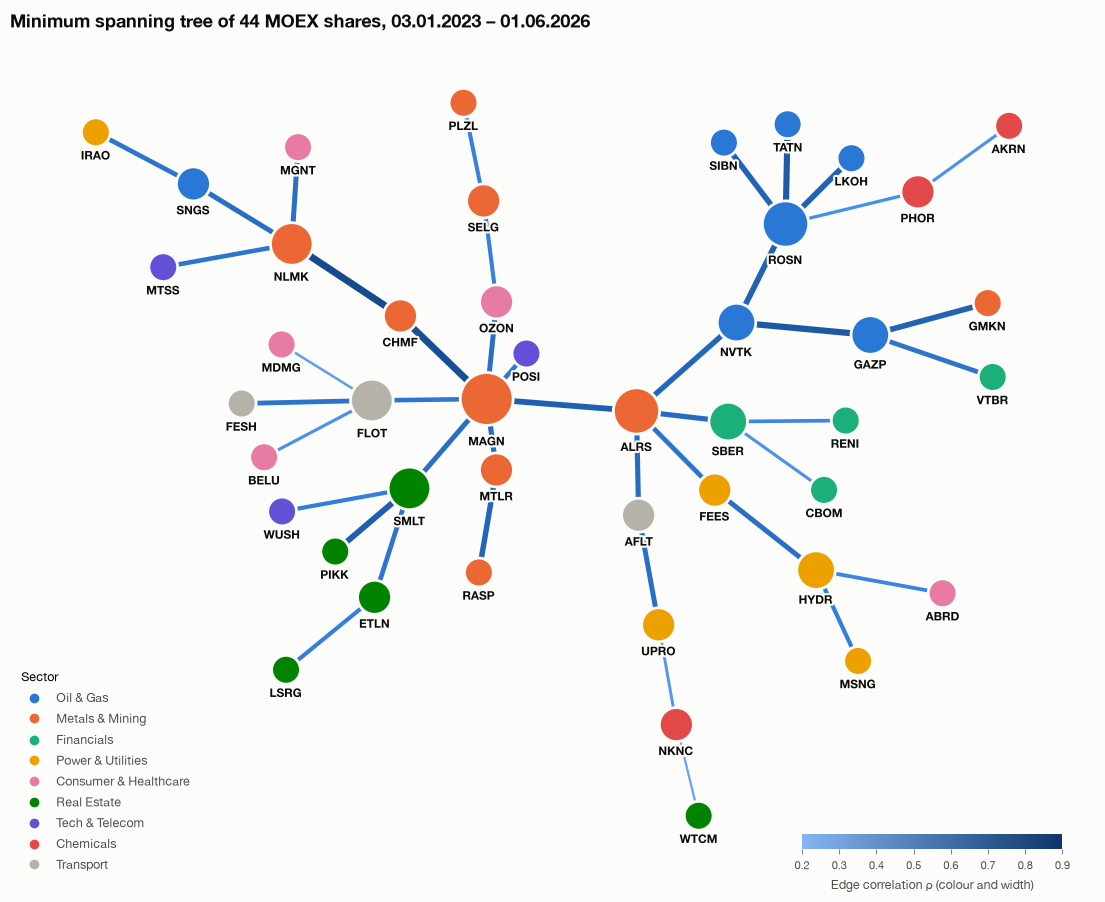

In [7]:
period = f"{prices.index[0]:%d.%m.%Y} – {prices.index[-1]:%d.%m.%Y}"
plotting.plot_mst(tree, f"Minimum spanning tree of 44 MOEX shares, {period}",
                  path=config.FIGURES_DIR / "mst.png");

Node colour shows the sector and node size shows the degree. Edge width and colour show
the correlation along the edge. Any two shares are joined by exactly one path, and the
tree has no cycles.